# Détection d'anomalies de roulements — CNN 1D, CNN 2D (GASF/GADF) et réseau siamois few-shot

Classification de signaux de roulements en 3 classes : **Normal**, **Inner Race Fault** et **Outer Race Fault**.

| Approche | Entrée | Modèle |
|---|---|---|
| 1D | signal temporel standardisé (5000 points) | Conv1D |
| 2D | image GASF (Gramian Angular Summation Field) | Conv2D |
| 2D | image GADF (Gramian Angular Difference Field) | Conv2D |
| Few-shot | image GASF, **20 exemples par classe** | réseau siamois (apprentissage de similarité) |

**Données** : dataset [SUBF v2.0 — Bearing Faults Sound Data](https://www.kaggle.com/datasets/sumairaziz/subf-v2-0-dataset-bearing-faults-sound-data).
Placez-le dans `Dataset/` (sous-dossiers `Normal/`, `Inner Race Fault/`, `Outer Race Fault/`) ou indiquez son chemin dans `DATASET_DIR`.
Sans dataset, le notebook utilise automatiquement le **jeu de démonstration** inclus (`data/demo/`, 100 signaux par classe).

Tous les modèles sont évalués sur **le même jeu de test**, qui n'est jamais utilisé pendant l'entraînement :
le choix des poids (early stopping) se fait uniquement sur le jeu de validation.

In [1]:
import os
import random
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, Model, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve)
from sklearn.preprocessing import label_binarize

from bearing_utils import (CLASS_NAMES, load_signals, dataset_available,
                           minmax, zscore, gaf_images, image_sequence)

# ───────────────────────── Configuration ─────────────────────────
DATASET_DIR = Path(os.environ.get("DATASET_DIR", "Dataset"))  # dataset SUBF v2.0 complet
CACHE_DIR = Path("cache")                                     # images GAF générées
MAX_SIGNALS_PER_CLASS = None   # None = tous les signaux (2160 par classe dans le dataset complet)

FULL_DATASET = dataset_available(DATASET_DIR)
IMAGE_SIZE = 1024 if FULL_DATASET else 256   # 1024x1024 comme dans l'étude ; 256 pour la démo
BATCH_SIZE_1D = 32
BATCH_SIZE_2D = 2 if IMAGE_SIZE >= 1024 else 16
EPOCHS_1D = 80
EPOCHS_2D = 25
PATIENCE = 8

FEW_SHOT_PER_CLASS = 20      # exemples d'entraînement par classe pour le réseau siamois
K_SHOTS = [1, 5]             # exemples de référence par classe à l'évaluation
N_EPISODES = 20              # épisodes aléatoires pour moyenner l'évaluation few-shot

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("Dataset complet trouvé :", FULL_DATASET)
print("Taille des images GAF  :", IMAGE_SIZE)

I0000 00:00:1795129174.646720    6607 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795129175.781162    6607 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Dataset complet trouvé : False
Taille des images GAF  : 256


In [2]:
# ───────────────────────── Chargement et découpage ─────────────────────────
X_raw, y, SOURCE = load_signals(DATASET_DIR, MAX_SIGNALS_PER_CLASS)
print("Source :", SOURCE)
print("Signaux :", X_raw.shape, "| par classe :", np.bincount(y))

# Découpage unique, partagé par tous les modèles : 60 % train / 20 % validation / 20 % test
idx_all = np.arange(len(y))
idx_train, idx_test = train_test_split(idx_all, test_size=0.20, stratify=y, random_state=SEED)
idx_train, idx_val = train_test_split(idx_train, test_size=0.25, stratify=y[idx_train], random_state=SEED)
y_train, y_val, y_test = y[idx_train], y[idx_val], y[idx_test]
print(f"Train : {len(idx_train)} | Validation : {len(idx_val)} | Test : {len(idx_test)}")

RESULTS = {}   # nom du modèle -> {"proba": probabilités sur le test, "metrics": scores}
y_test_bin = label_binarize(y_test, classes=np.arange(len(CLASS_NAMES)))


def metrics(proba):
    y_pred = proba.argmax(axis=1)
    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1 macro": f1_score(y_test, y_pred, average="macro"),
        "AUC macro": roc_auc_score(y_test_bin, proba, average="macro", multi_class="ovr"),
    }


def early_stopping():
    # Sélection des poids sur la VALIDATION uniquement (jamais sur le test)
    return EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1)


def report(name, proba):
    """Affiche et enregistre les performances d'un modèle sur le jeu de test."""
    y_pred = proba.argmax(axis=1)
    m = metrics(proba)
    RESULTS[name] = {"proba": proba, "metrics": m}
    print(f"\n========== {name} ==========")
    print(f"Accuracy       : {m['Accuracy']:.4f}")
    print(f"F1-score macro : {m['F1 macro']:.4f}")
    print(f"AUC macro      : {m['AUC macro']:.4f}")
    print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, zero_division=0))


def plot_history(history, title):
    plt.figure(figsize=(7, 3.5))
    plt.plot(history.history["accuracy"], label="Train")
    plt.plot(history.history["val_accuracy"], label="Validation")
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True, alpha=0.4)
    plt.show()

Source : jeu de démonstration (data/demo)
Signaux : (300, 5000) | par classe : [100 100 100]
Train : 180 | Validation : 60 | Test : 60


## 1. Conv1D sur les signaux temporels

Epoch 1/80


6/6 - 2s - 353ms/step - accuracy: 0.3222 - loss: 1.0953 - val_accuracy: 0.3333 - val_loss: 1.0986


Epoch 2/80


6/6 - 1s - 89ms/step - accuracy: 0.2778 - loss: 1.1095 - val_accuracy: 0.3333 - val_loss: 1.0984


Epoch 3/80


6/6 - 1s - 96ms/step - accuracy: 0.3167 - loss: 1.1028 - val_accuracy: 0.3333 - val_loss: 1.0985


... (152 outputs left out)

Epoch 80/80


6/6 - 1s - 106ms/step - accuracy: 0.6833 - loss: 0.5254 - val_accuracy: 0.7833 - val_loss: 0.4584


Restoring model weights from the end of the best epoch: 76.



========== Conv1D ==========
Accuracy       : 0.7167
F1-score macro : 0.6703
AUC macro      : 0.9567
                  precision    recall  f1-score   support

          Normal       0.80      0.20      0.32        20
Inner Race Fault       0.54      0.95      0.69        20
Outer Race Fault       1.00      1.00      1.00        20

        accuracy                           0.72        60
       macro avg       0.78      0.72      0.67        60
    weighted avg       0.78      0.72      0.67        60



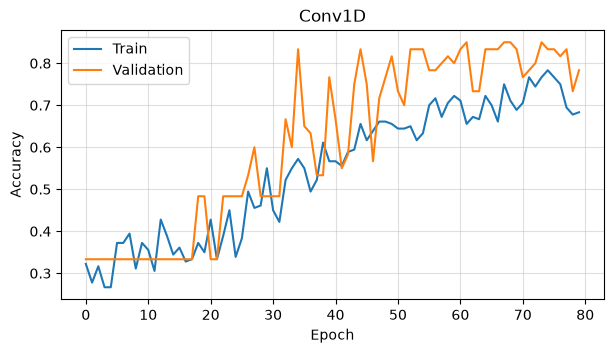

In [3]:
X_1d = zscore(X_raw)[..., np.newaxis]


def build_conv1d(input_shape, n_classes=3):
    inputs = Input(shape=input_shape)
    x = layers.Conv1D(32, 15, padding="same", activation="relu")(inputs)
    x = layers.MaxPooling1D(4)(x)
    x = layers.Dropout(0.10)(x)
    x = layers.Conv1D(64, 9, padding="same", activation="relu")(x)
    x = layers.MaxPooling1D(4)(x)
    x = layers.Dropout(0.15)(x)
    x = layers.Conv1D(128, 5, padding="same", activation="relu")(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(128, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(96, activation="relu")(x)
    x = layers.Dropout(0.30)(x)
    outputs = layers.Dense(n_classes, activation="softmax")(x)
    model = Model(inputs, outputs, name="Conv1D")
    model.compile(optimizer=Adam(3e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


model_1d = build_conv1d(X_1d.shape[1:], len(CLASS_NAMES))
history_1d = model_1d.fit(
    X_1d[idx_train], y_train,
    validation_data=(X_1d[idx_val], y_val),
    epochs=EPOCHS_1D, batch_size=BATCH_SIZE_1D,
    callbacks=[early_stopping()], verbose=2,
)
report("Conv1D", model_1d.predict(X_1d[idx_test], verbose=0))
plot_history(history_1d, "Conv1D")

## 2. Conv2D sur images GASF et GADF

Chaque signal (normalisé Min-Max) est transformé en image Gramian Angular Field.
Les images sont générées une seule fois puis gardées en cache dans `cache/`.

In [4]:
X_mm = minmax(X_raw)
images_gasf = gaf_images(X_mm, "summation", IMAGE_SIZE, CACHE_DIR)
images_gadf = gaf_images(X_mm, "difference", IMAGE_SIZE, CACHE_DIR)


def build_conv2d(input_shape, n_classes=3, name="Conv2D"):
    # Premier filtre avec un pas proportionnel à la taille de l'image (8 pour 1024x1024)
    stride = max(1, input_shape[0] // 128)
    inputs = Input(shape=input_shape)
    x = layers.Conv2D(16, 11, strides=stride, padding="same", activation="relu")(inputs)
    x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.Conv2D(32, 5, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.Dropout(0.12)(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.Dropout(0.20)(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.35)(x)
    outputs = layers.Dense(n_classes, activation="softmax")(x)
    model = Model(inputs, outputs, name=name)
    model.compile(optimizer=Adam(5e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


def train_conv2d(images, name, train_idx=idx_train, train_y=y_train):
    model = build_conv2d(images.shape[1:], len(CLASS_NAMES), name=re.sub(r"\W+", "_", name).strip("_"))
    history = model.fit(
        image_sequence(images, train_idx, train_y, BATCH_SIZE_2D, shuffle=True, seed=SEED),
        validation_data=image_sequence(images, idx_val, y_val, BATCH_SIZE_2D, shuffle=False),
        epochs=EPOCHS_2D, callbacks=[early_stopping()], verbose=2,
    )
    proba = model.predict(image_sequence(images, idx_test, y_test, BATCH_SIZE_2D, shuffle=False), verbose=0)
    report(name, proba)
    plot_history(history, name)
    return model

Cache trouvé : cache/summation_256_300.dat
Cache trouvé : cache/difference_256_300.dat


Epoch 1/25


12/12 - 5s - 393ms/step - accuracy: 0.4333 - loss: 1.1678 - val_accuracy: 0.3333 - val_loss: 1.4101


Epoch 2/25


12/12 - 3s - 236ms/step - accuracy: 0.4833 - loss: 1.0206 - val_accuracy: 0.3333 - val_loss: 2.1528


Epoch 3/25


12/12 - 3s - 237ms/step - accuracy: 0.5611 - loss: 0.7843 - val_accuracy: 0.3500 - val_loss: 1.4396


... (42 outputs left out)

Epoch 25/25


12/12 - 3s - 233ms/step - accuracy: 0.8333 - loss: 0.3623 - val_accuracy: 0.5667 - val_loss: 1.9280


Restoring model weights from the end of the best epoch: 19.



========== Conv2D GASF ==========
Accuracy       : 0.7000
F1-score macro : 0.6581
AUC macro      : 0.8633
                  precision    recall  f1-score   support

          Normal       0.53      0.90      0.67        20
Inner Race Fault       0.67      0.20      0.31        20
Outer Race Fault       1.00      1.00      1.00        20

        accuracy                           0.70        60
       macro avg       0.73      0.70      0.66        60
    weighted avg       0.73      0.70      0.66        60



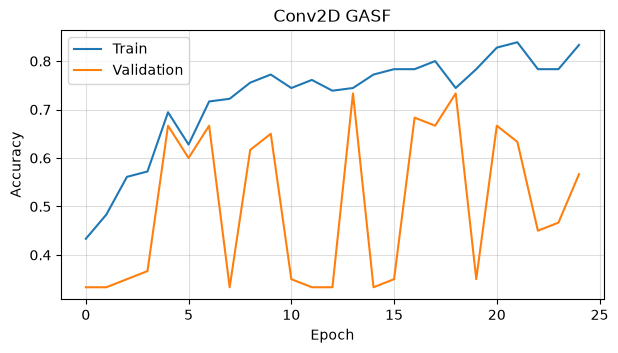

In [5]:
model_gasf = train_conv2d(images_gasf, "Conv2D GASF")

Epoch 1/25


12/12 - 5s - 421ms/step - accuracy: 0.4056 - loss: 1.1806 - val_accuracy: 0.3333 - val_loss: 1.5321


Epoch 2/25


12/12 - 3s - 244ms/step - accuracy: 0.4556 - loss: 1.0295 - val_accuracy: 0.3333 - val_loss: 3.6714


Epoch 3/25


12/12 - 3s - 250ms/step - accuracy: 0.5944 - loss: 0.7308 - val_accuracy: 0.3333 - val_loss: 4.8727


... (33 outputs left out)

12/12 - 3s - 248ms/step - accuracy: 0.6833 - loss: 0.5824 - val_accuracy: 0.3333 - val_loss: 5.5170


Epoch 20: early stopping


Restoring model weights from the end of the best epoch: 12.



========== Conv2D GADF ==========
Accuracy       : 0.7000
F1-score macro : 0.6238
AUC macro      : 0.8546
                  precision    recall  f1-score   support

          Normal       0.53      1.00      0.69        20
Inner Race Fault       1.00      0.10      0.18        20
Outer Race Fault       1.00      1.00      1.00        20

        accuracy                           0.70        60
       macro avg       0.84      0.70      0.62        60
    weighted avg       0.84      0.70      0.62        60



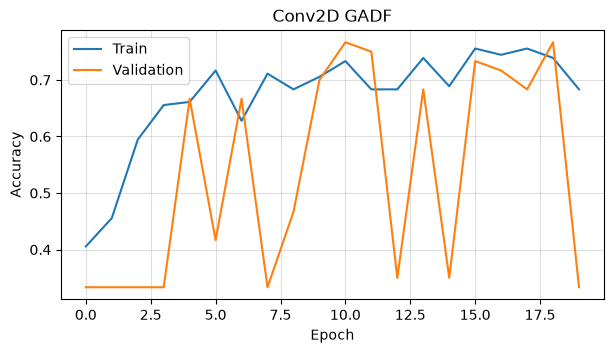

In [6]:
model_gadf = train_conv2d(images_gadf, "Conv2D GADF")

## 3. Réseau siamois few-shot (images GASF)

Le réseau siamois n'apprend pas à classer directement : il apprend une **mesure de similarité** entre deux images.
Deux branches identiques (poids partagés) produisent un vecteur pour chaque image, et une tête estime la
probabilité que les deux images appartiennent à la même classe.

- **Entraînement** : seulement `FEW_SHOT_PER_CLASS` = 20 exemples par classe, à partir desquels on forme des paires « même classe » / « classes différentes ».
- **Évaluation (3-way, K-shot)** : pour chaque signal de test, on le compare à K exemples de référence par classe et on prédit la classe la plus similaire. Le résultat est moyenné sur plusieurs tirages des exemples de référence.
- **Point de comparaison** : un Conv2D GASF classique entraîné sur les mêmes 20 exemples par classe.

Epoch 1/40


37/37 - 7s - 199ms/step - accuracy: 0.6461 - loss: 0.6712 - val_accuracy: 0.6150 - val_loss: 0.6399


Epoch 2/40


37/37 - 6s - 164ms/step - accuracy: 0.7238 - loss: 0.5968 - val_accuracy: 0.7000 - val_loss: 0.5841


Epoch 3/40


37/37 - 7s - 178ms/step - accuracy: 0.7728 - loss: 0.4898 - val_accuracy: 0.8050 - val_loss: 0.4340


... (18 outputs left out)

Epoch 13/40


37/37 - 6s - 160ms/step - accuracy: 0.9992 - loss: 0.0189 - val_accuracy: 0.7483 - val_loss: 1.1161


Epoch 13: early stopping


Restoring model weights from the end of the best epoch: 5.


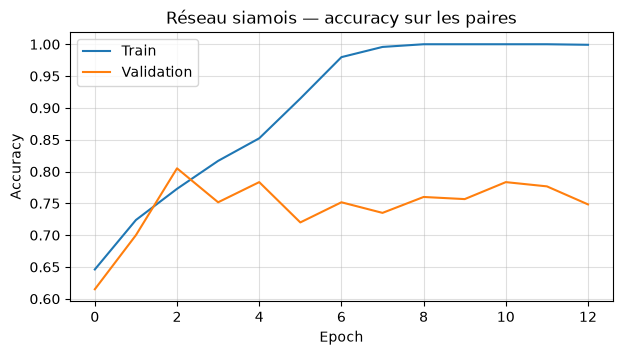

In [7]:
rng = np.random.default_rng(SEED)

# Sous-ensemble few-shot : FEW_SHOT_PER_CLASS exemples par classe, tirés du jeu d'entraînement
fs_idx = np.concatenate([
    rng.choice(idx_train[y_train == c], FEW_SHOT_PER_CLASS, replace=False)
    for c in range(len(CLASS_NAMES))
])
fs_y = y[fs_idx]
X_fs = np.asarray(images_gasf[np.sort(fs_idx)], dtype="float32")[np.argsort(np.argsort(fs_idx))]

# Validation : jusqu'à 30 images par classe (pour l'early stopping des paires)
val_sub = np.concatenate([idx_val[y_val == c][:30] for c in range(len(CLASS_NAMES))])
X_vsub = np.asarray(images_gasf[np.sort(val_sub)], dtype="float32")
y_vsub = y[np.sort(val_sub)]


def make_pairs(X, labels, n_pairs, rng):
    """Paires équilibrées : moitié même classe (cible 1), moitié classes différentes (cible 0)."""
    by_class = [np.where(labels == c)[0] for c in range(len(CLASS_NAMES))]
    a, b, t = [], [], []
    for k in range(n_pairs):
        c1 = rng.integers(len(CLASS_NAMES))
        if k % 2 == 0:
            i, j = rng.choice(by_class[c1], 2, replace=False)
            t.append(1.0)
        else:
            c2 = rng.choice([c for c in range(len(CLASS_NAMES)) if c != c1])
            i, j = rng.choice(by_class[c1]), rng.choice(by_class[c2])
            t.append(0.0)
        a.append(i)
        b.append(j)
    return (X[a], X[b]), np.asarray(t, dtype="float32")


class PairSequence(tf.keras.utils.Sequence):
    """Nouvelles paires aléatoires à chaque epoch."""
    def __init__(self, X, labels, pairs_per_epoch=1200, batch_size=32, seed=SEED):
        super().__init__()
        self.X, self.labels, self.batch_size = X, labels, batch_size
        self.n, self.rng = pairs_per_epoch, np.random.default_rng(seed)
        self.on_epoch_end()

    def __len__(self):
        return self.n // self.batch_size

    def __getitem__(self, i):
        s = slice(i * self.batch_size, (i + 1) * self.batch_size)
        return (self.pairs[0][0][s], self.pairs[0][1][s]), self.pairs[1][s]

    def on_epoch_end(self):
        self.pairs = make_pairs(self.X, self.labels, self.n, self.rng)


def build_embedding(input_shape, dim=64):
    inputs = Input(shape=input_shape)
    x = inputs
    if input_shape[0] > 256:                      # 1024 → 256 pour garder un réseau léger
        x = layers.AveragePooling2D(input_shape[0] // 256)(x)
    x = layers.Conv2D(16, 5, strides=2, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dim)(x)
    outputs = layers.UnitNormalization()(x)
    return Model(inputs, outputs, name="embedding")


embedding = build_embedding(images_gasf.shape[1:])

# Tête de similarité : |e1 - e2| -> probabilité "même classe"
diff_in = Input(shape=(embedding.output_shape[-1],))
h = layers.Dense(32, activation="relu")(diff_in)
head = Model(diff_in, layers.Dense(1, activation="sigmoid")(h), name="similarity_head")

in_a = Input(shape=images_gasf.shape[1:])
in_b = Input(shape=images_gasf.shape[1:])
distance = layers.Lambda(lambda t: tf.abs(t[0] - t[1]))([embedding(in_a), embedding(in_b)])
siamese = Model([in_a, in_b], head(distance), name="siamese")
siamese.compile(optimizer=Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])

val_pairs = make_pairs(X_vsub, y_vsub, 600, np.random.default_rng(SEED + 1))
history_siam = siamese.fit(
    PairSequence(X_fs, fs_y),
    validation_data=val_pairs,
    epochs=40, callbacks=[early_stopping()], verbose=2,
)
plot_history(history_siam, "Réseau siamois — accuracy sur les paires")

In [8]:
# ───────────── Évaluation few-shot 3-way K-shot sur le jeu de test ─────────────
emb_test = embedding.predict(
    image_sequence(images_gasf, idx_test, y_test, BATCH_SIZE_2D, shuffle=False), verbose=0)
emb_fs = embedding.predict(X_fs, verbose=0)


def few_shot_scores(k, rng):
    """Similarité moyenne de chaque signal de test avec K références par classe."""
    scores = np.zeros((len(emb_test), len(CLASS_NAMES)), dtype="float32")
    for c in range(len(CLASS_NAMES)):
        support = emb_fs[rng.choice(np.where(fs_y == c)[0], k, replace=False)]
        diffs = np.abs(emb_test[:, None, :] - support[None, :, :]).reshape(-1, emb_fs.shape[1])
        scores[:, c] = head.predict(diffs, verbose=0).reshape(len(emb_test), k).mean(axis=1)
    return scores


ep_rng = np.random.default_rng(SEED)
for k in K_SHOTS:
    episodes = []
    for _ in range(N_EPISODES):
        s = few_shot_scores(k, ep_rng)
        episodes.append(s / s.sum(axis=1, keepdims=True))
    ep_metrics = pd.DataFrame([metrics(p) for p in episodes])
    name = f"Siamois {k}-shot ({FEW_SHOT_PER_CLASS}/classe)"
    # Scores = moyenne sur les épisodes ; matrice de confusion et ROC = épisode médian
    median_ep = int(np.argsort(ep_metrics["Accuracy"].values)[len(episodes) // 2])
    RESULTS[name] = {"proba": episodes[median_ep], "metrics": ep_metrics.mean().to_dict()}
    print(f"\n========== {name} — moyenne sur {N_EPISODES} épisodes ==========")
    for col in ep_metrics:
        print(f"{col:<15}: {ep_metrics[col].mean():.4f} ± {ep_metrics[col].std():.4f}")


========== Siamois 1-shot (20/classe) — moyenne sur 20 épisodes ==========
Accuracy       : 0.6533 ± 0.0353
F1 macro       : 0.6291 ± 0.0358
AUC macro      : 0.8280 ± 0.0029



========== Siamois 5-shot (20/classe) — moyenne sur 20 épisodes ==========
Accuracy       : 0.6550 ± 0.0172
F1 macro       : 0.6378 ± 0.0109
AUC macro      : 0.8285 ± 0.0015


Epoch 1/25


4/4 - 4s - 943ms/step - accuracy: 0.3500 - loss: 1.1439 - val_accuracy: 0.3333 - val_loss: 1.1256


Epoch 2/25


4/4 - 1s - 304ms/step - accuracy: 0.5667 - loss: 0.9453 - val_accuracy: 0.3333 - val_loss: 1.3780


Epoch 3/25


4/4 - 1s - 306ms/step - accuracy: 0.5667 - loss: 0.8457 - val_accuracy: 0.3333 - val_loss: 1.8649


... (11 outputs left out)

4/4 - 2s - 379ms/step - accuracy: 0.7667 - loss: 0.4771 - val_accuracy: 0.3333 - val_loss: 3.4957


Epoch 9: early stopping


Restoring model weights from the end of the best epoch: 1.



========== Conv2D GASF (20/classe) ==========
Accuracy       : 0.3333
F1-score macro : 0.1667
AUC macro      : 0.6533
                  precision    recall  f1-score   support

          Normal       0.00      0.00      0.00        20
Inner Race Fault       0.33      1.00      0.50        20
Outer Race Fault       0.00      0.00      0.00        20

        accuracy                           0.33        60
       macro avg       0.11      0.33      0.17        60
    weighted avg       0.11      0.33      0.17        60



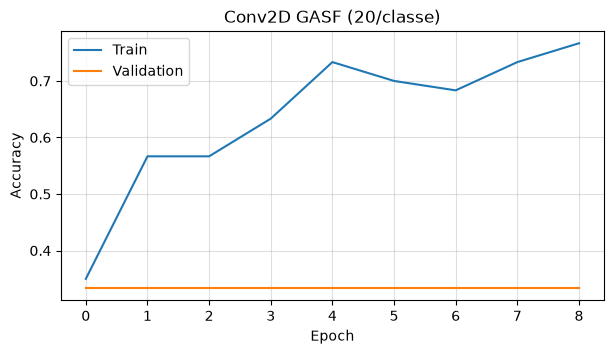

In [9]:
# Point de comparaison : CNN classique entraîné sur les mêmes 20 exemples par classe
model_fs_baseline = train_conv2d(images_gasf, f"Conv2D GASF ({FEW_SHOT_PER_CLASS}/classe)",
                                 train_idx=fs_idx, train_y=fs_y)

## 4. Comparaison finale

Source des données : jeu de démonstration (data/demo) | signaux de test : 60


,Accuracy,F1 macro,AUC macro
Modèle,,,
Conv1D,0.7167,0.6703,0.9567
Conv2D GASF,0.7000,0.6581,0.8633
Conv2D GADF,0.7000,0.6238,0.8546
Siamois 1-shot (20/classe),0.6533,0.6291,0.8280
Siamois 5-shot (20/classe),0.6550,0.6378,0.8285
Conv2D GASF (20/classe),0.3333,0.1667,0.6533


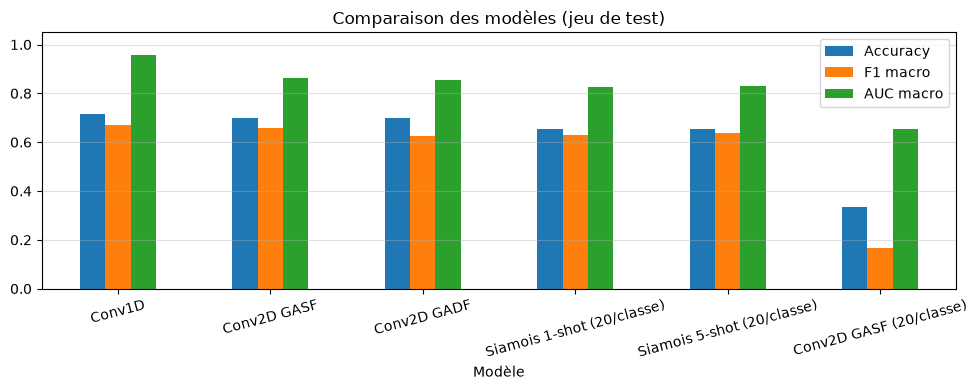

In [10]:
summary = pd.DataFrame({name: r["metrics"] for name, r in RESULTS.items()}).T.round(4)
summary.index.name = "Modèle"
print("Source des données :", SOURCE, "| signaux de test :", len(y_test))
display(summary)

ax = summary.plot.bar(figsize=(10, 4), rot=15, ylim=(0, 1.05))
ax.set_title("Comparaison des modèles (jeu de test)")
ax.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.show()

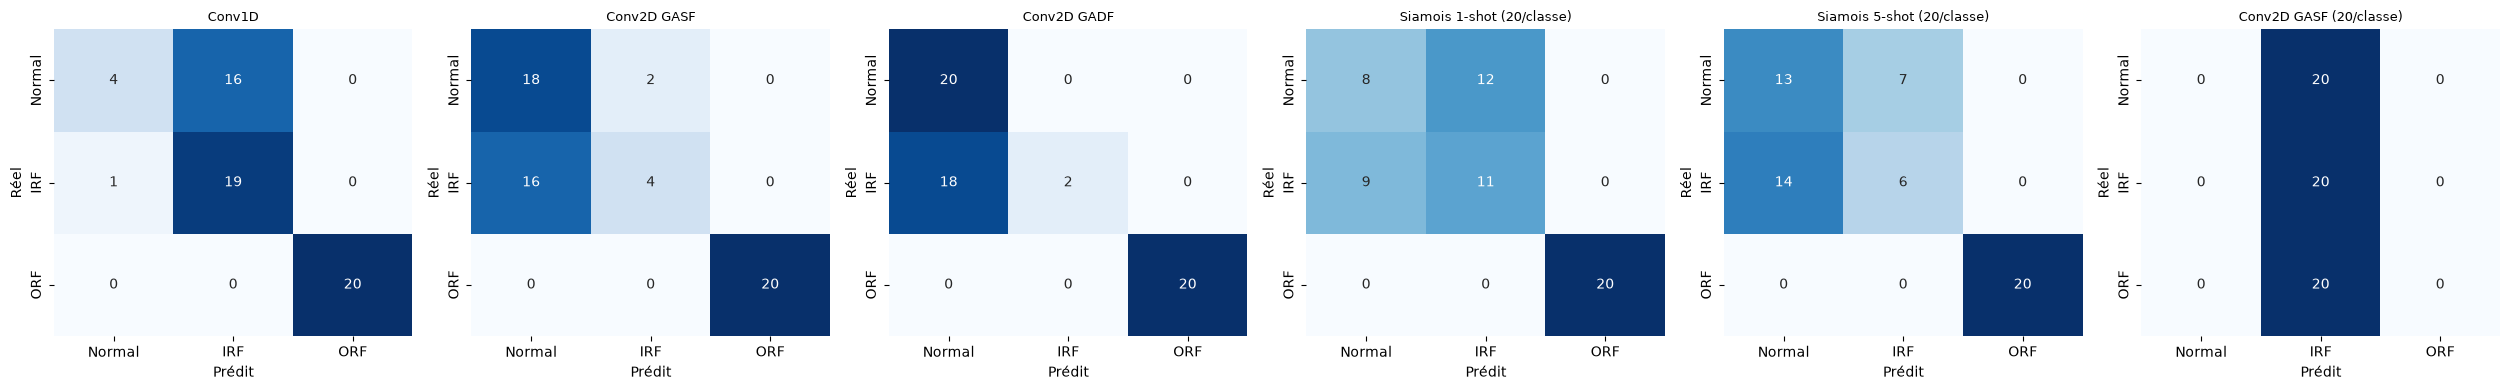

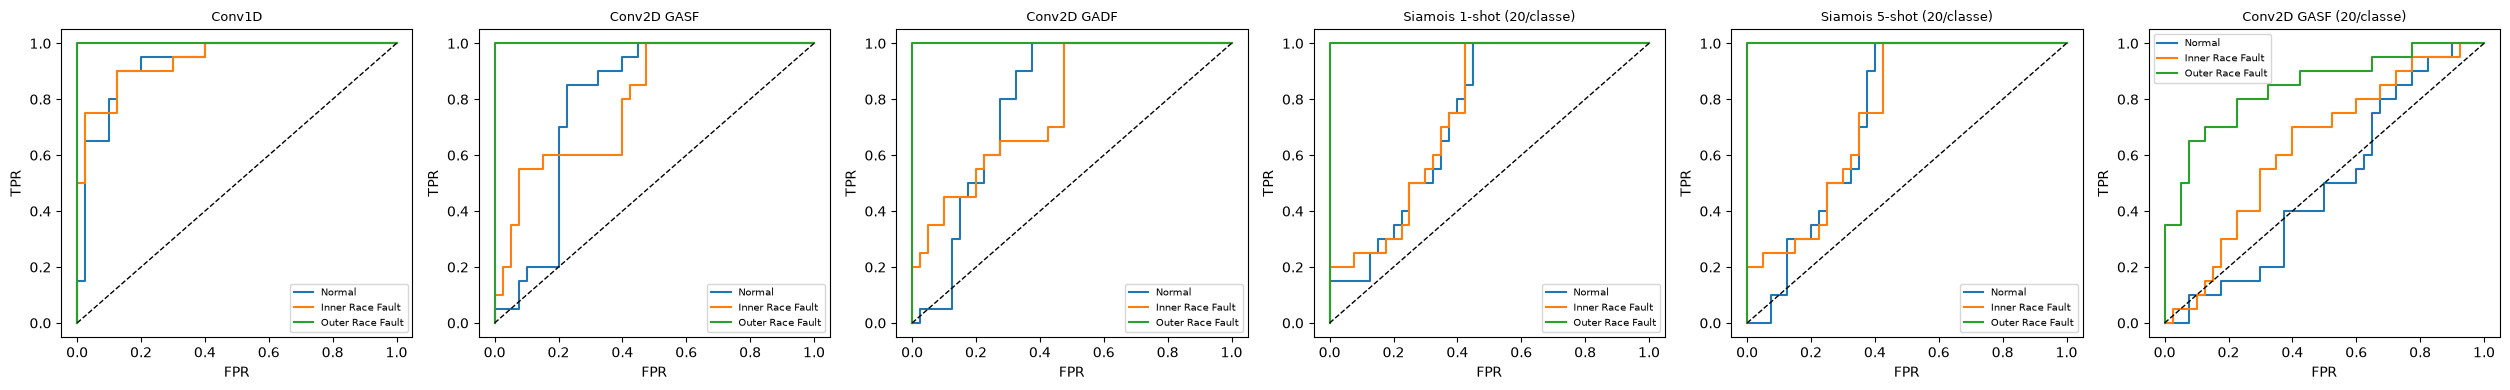

In [11]:
# Matrices de confusion
fig, axes = plt.subplots(1, len(RESULTS), figsize=(4.2 * len(RESULTS), 4))
for ax, (name, res) in zip(np.atleast_1d(axes), RESULTS.items()):
    proba = res["proba"]
    cm = confusion_matrix(y_test, proba.argmax(axis=1))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Normal", "IRF", "ORF"], yticklabels=["Normal", "IRF", "ORF"])
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("Prédit")
    ax.set_ylabel("Réel")
plt.tight_layout()
plt.show()

# Courbes ROC (une classe contre les autres)
fig, axes = plt.subplots(1, len(RESULTS), figsize=(4.2 * len(RESULTS), 4))
for ax, (name, res) in zip(np.atleast_1d(axes), RESULTS.items()):
    proba = res["proba"]
    for c, cname in enumerate(CLASS_NAMES):
        fpr, tpr, _ = roc_curve(y_test_bin[:, c], proba[:, c])
        ax.plot(fpr, tpr, label=cname)
    ax.plot([0, 1], [0, 1], "k--", linewidth=1)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("FPR")
    ax.set_ylabel("TPR")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()